# Oblique Forest Simulation Comparisons

This notebook generates the simulated datasets proposed in `forestgap/oblique_rf_simulations.md` and compares three model families on each one:

- RandomForest
- RotationForest
- ObliqueRandomForest

For each simulated dataset, the notebook reports held-out classification accuracy and shows proximity-based PHATE embeddings side-by-side.

The simulation list includes the original ideas plus additional oblique-friendly alternatives such as a sparse hyperplane, an oblique slab, and a dual-projection XOR.


In [ ]:
from pathlib import Path
import sys

# Add parent directory to path to import local forestgap package
sys.path.insert(0, str(Path.cwd().parent))

import inspect
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

from forestgap import load_simulated_dataset, with_sparse_proximity

warnings.filterwarnings(
    "ignore",
    message=r".*BaseEstimator\._validate_data.*",
    category=FutureWarning,
)

try:
    from aeon.classification.sklearn import RotationForestClassifier
except Exception as exc:
    raise ImportError("RotationForestClassifier from aeon is required for this notebook.") from exc

try:
    from treeple import ObliqueRandomForestClassifier
except Exception as exc:
    raise ImportError("ObliqueRandomForestClassifier from treeple is required for this notebook.") from exc

try:
    import phate
except Exception as exc:
    raise ImportError("PHATE is required for this notebook. Install with `pip install phate`.") from exc

c:\Users\rhodes8\AppData\Local\miniconda3\envs\generalprox\Lib\site-packages\aeon\base\__init__.py:24: FutureWarning: The aeon package will soon be releasing v1.0.0 with the removal of legacy modules and interfaces such as BaseTransformer and BaseForecaster. This will contain breaking changes. See aeon-toolkit.org for more information. Set aeon.AEON_DEPRECATION_WARNING or the AEON_DEPRECATION_WARNING environmental variable to 'False' to disable this warning.
  warnings.warn(


## Configuration

The defaults below keep runtime reasonable while still making the geometric differences visible.


In [2]:
RANDOM_STATE = 42
TEST_SIZE = 0.30
N_ESTIMATORS = 75
N_JOBS = -1
PROX_METHOD = "rfgap"

SIMULATION_CONFIGS = [
    {
        "name": "rotated_linear_boundary",
        "title": "Rotated Linear Boundary",
        "kwargs": {"n_samples": 350, "n_features": 6, "angle_degrees": 35.0, "noise_std": 0.25},
    },
    {
        "name": "rotated_xor",
        "title": "Rotated XOR",
        "kwargs": {"n_samples": 350, "n_features": 6, "angle_degrees": 35.0, "feature_noise_std": 0.10},
    },
    {
        "name": "oblique_gaussian_clusters",
        "title": "Oblique Gaussian Clusters",
        "kwargs": {"n_samples": 350, "n_features": 6, "correlation": 0.85, "class_sep": 2.5, "angle_degrees": 25.0},
    },
    {
        "name": "rotated_subspace_signal",
        "title": "Rotated Subspace Signal",
        "kwargs": {"n_samples": 400, "n_features": 10, "signal_noise_std": 0.25, "feature_noise_std": 0.50},
    },
    {
        "name": "additive_interaction_correlated",
        "title": "Additive Interaction with Correlation",
        "kwargs": {"n_samples": 400, "n_features": 6, "correlation": 0.70, "noise_std": 0.20},
    },
    {
        "name": "diagonal_band",
        "title": "Diagonal Band",
        "kwargs": {"n_samples": 350, "n_features": 6, "band_width": 0.45, "noise_std": 0.05},
    },
    {
        "name": "sparse_oblique_hyperplane",
        "title": "Sparse Oblique Hyperplane",
        "kwargs": {"n_samples": 400, "n_features": 12, "n_informative": 4, "margin_noise_std": 0.20},
    },
    {
        "name": "oblique_slab",
        "title": "Oblique Slab",
        "kwargs": {"n_samples": 400, "n_features": 8, "slab_half_width": 0.40, "margin_noise_std": 0.05},
    },
    {
        "name": "dual_projection_xor",
        "title": "Dual-Projection XOR",
        "kwargs": {"n_samples": 400, "n_features": 8, "projection_noise_std": 0.10},
    },
]

MODEL_SPECS = [
    ("RandomForest", RandomForestClassifier, "#1f77b4"),
    ("RotationForest", RotationForestClassifier, "#ff7f0e"),
    ("ObliqueRandomForest", ObliqueRandomForestClassifier, "#2ca02c"),
]

print(f"Simulations: {len(SIMULATION_CONFIGS)}")
print(f"Models: {[name for name, _, _ in MODEL_SPECS]}")


Simulations: 9
Models: ['RandomForest', 'RotationForest', 'ObliqueRandomForest']


## Helpers

These helpers fit proximity-enabled models, compute PHATE embeddings on the training proximities, and create one comparison figure per simulated dataset.


In [3]:
def to_dense(matrix):
    return matrix.toarray() if sparse.issparse(matrix) else np.asarray(matrix)


def phate_from_proximity(proximity_matrix, random_state=42):
    op = phate.PHATE(random_state=random_state, n_jobs=N_JOBS)
    return op.fit_transform(to_dense(proximity_matrix))


def build_supervised_model(model_cls):
    prox_cls = with_sparse_proximity(model_cls)
    base_sig = inspect.signature(model_cls.__init__)
    kwargs = {
        "n_estimators": N_ESTIMATORS,
        "random_state": RANDOM_STATE,
        "prox_method": PROX_METHOD,
        "matrix_type": "dense",
    }
    if "n_jobs" in base_sig.parameters:
        kwargs["n_jobs"] = N_JOBS
    if "bootstrap" in base_sig.parameters:
        kwargs["bootstrap"] = True
    if "oob_score" in base_sig.parameters:
        kwargs["oob_score"] = False
    return prox_cls(**kwargs)


def fit_model_bundle(model_name, model_cls, X_train, y_train, X_test, y_test):
    model = build_supervised_model(model_cls)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    proximity = model.get_proximities()
    embedding = phate_from_proximity(proximity, random_state=RANDOM_STATE)
    return {
        "name": model_name,
        "model": model,
        "accuracy": accuracy,
        "proximity": proximity,
        "embedding": embedding,
    }


def plot_embedding(ax, embedding, labels, title):
    ax.scatter(embedding[:, 0], embedding[:, 1], c=labels, s=18, alpha=0.9, cmap="tab10")
    ax.set_title(title)
    ax.set_xlabel("PHATE-1")
    ax.set_ylabel("PHATE-2")


def run_single_simulation(simulation_spec):
    dataset = load_simulated_dataset(
        simulation_spec["name"],
        random_state=RANDOM_STATE,
        **simulation_spec["kwargs"],
    )
    X_train, X_test, y_train, y_test = train_test_split(
        dataset.X, dataset.y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=dataset.y,
    )

    bundles = []
    for model_name, model_cls, color in MODEL_SPECS:
        bundle = fit_model_bundle(model_name, model_cls, X_train, y_train, X_test, y_test)
        bundle["color"] = color
        bundles.append(bundle)

    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    for ax, bundle in zip(axes[:3], bundles):
        plot_embedding(ax, bundle["embedding"], y_train, f"{bundle['name']} PHATE")

    perf_ax = axes[3]
    perf_ax.bar(
        [bundle["name"] for bundle in bundles],
        [bundle["accuracy"] for bundle in bundles],
        color=[bundle["color"] for bundle in bundles],
    )
    perf_ax.set_ylim(0.0, 1.0)
    perf_ax.set_ylabel("Test Accuracy")
    perf_ax.set_title("Held-out Performance")
    perf_ax.tick_params(axis="x", rotation=20)

    fig.suptitle(
        f"{simulation_spec['title']} | n={dataset.X.shape[0]}, p={dataset.X.shape[1]}",
        fontsize=14,
    )
    plt.tight_layout()
    plt.show()

    rows = [
        {
            "dataset": simulation_spec["title"],
            "model": bundle["name"],
            "accuracy": bundle["accuracy"],
        }
        for bundle in bundles
    ]
    return rows


## Run All Simulations

Each simulation below produces one four-panel figure: three proximity PHATE plots and one test-accuracy bar chart.


Running simulation: rotated_linear_boundary
Calculating PHATE...
  Running PHATE on 245 observations and 245 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.11 seconds.
    Calculating KNN search...
    Calculated KNN search in 2.32 seconds.
    Calculating affinities...
    Calculated affinities in 1.67 seconds.
  Calculated graph and diffusion operator in 4.11 seconds.
  Calculating optimal t...
    Automatically selected t = 15
  Calculated optimal t in 0.12 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
  Calculated metric MDS in 0.27 seconds.
Calculated PHATE in 4.52 seconds.
Calculating PHATE...
  Running PHATE on 245 observations and 245 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.11 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.01 seconds.
    Calculating affinities...
    Calculated affinities in 0.02 seconds.
  

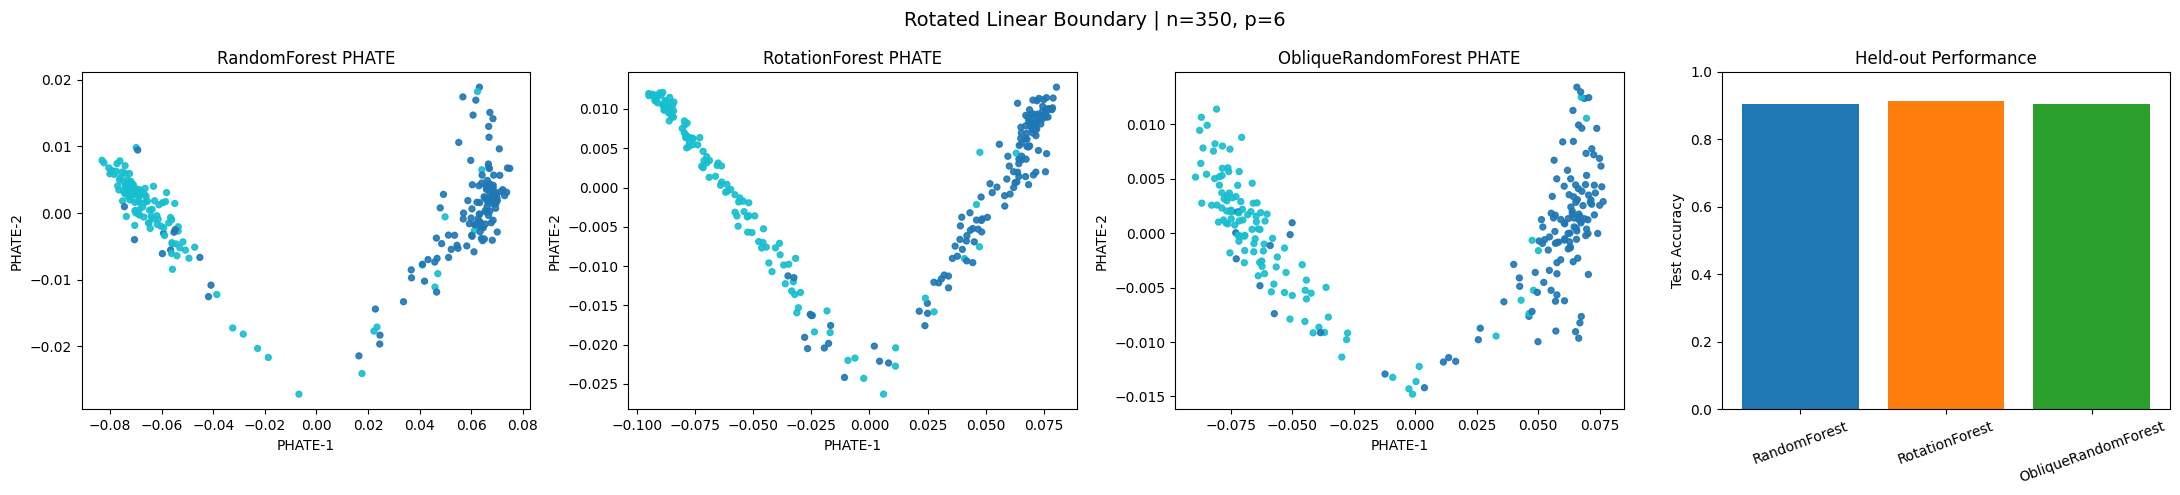

Running simulation: rotated_xor
Calculating PHATE...
  Running PHATE on 245 observations and 245 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.11 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.02 seconds.
    Calculating affinities...
  Calculated graph and diffusion operator in 0.13 seconds.
  Calculating optimal t...
    Automatically selected t = 15
  Calculated optimal t in 0.10 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.01 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -2.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.27 seconds.
Calculated PHATE in 0.52 seconds.
Calculating PHATE...
  Running PHATE on 245 observations and 245 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.11 seconds.
    Calculating K

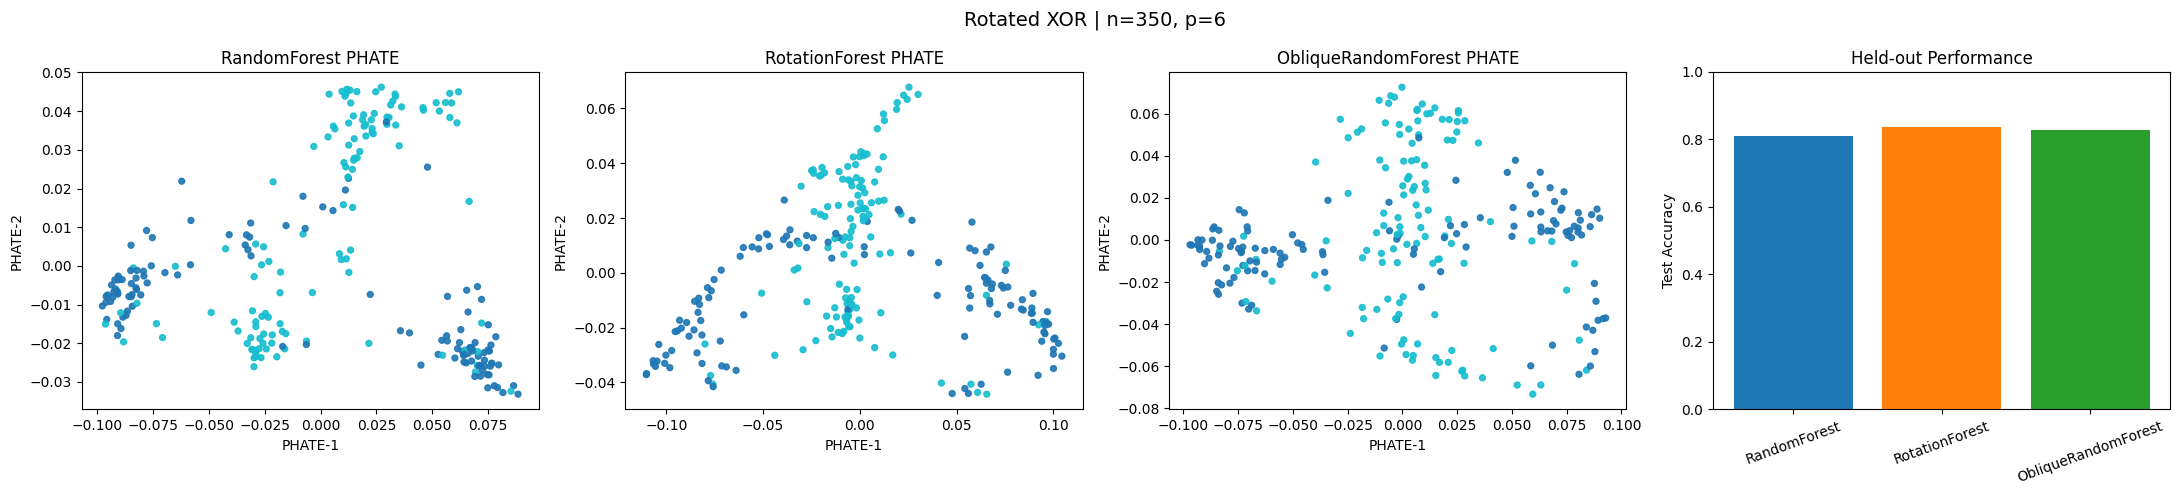

Running simulation: oblique_gaussian_clusters
Calculating PHATE...
  Running PHATE on 245 observations and 245 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.10 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.01 seconds.
    Calculating affinities...
    Calculated affinities in 0.02 seconds.
  Calculated graph and diffusion operator in 0.14 seconds.
  Calculating optimal t...
    Automatically selected t = 16
  Calculated optimal t in 0.10 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.8% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.26 seconds.
Calculated PHATE in 0.52 seconds.
Calculating PHATE...
  Running PHATE on 245 observations and 245 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.12 seconds.
    Calcul

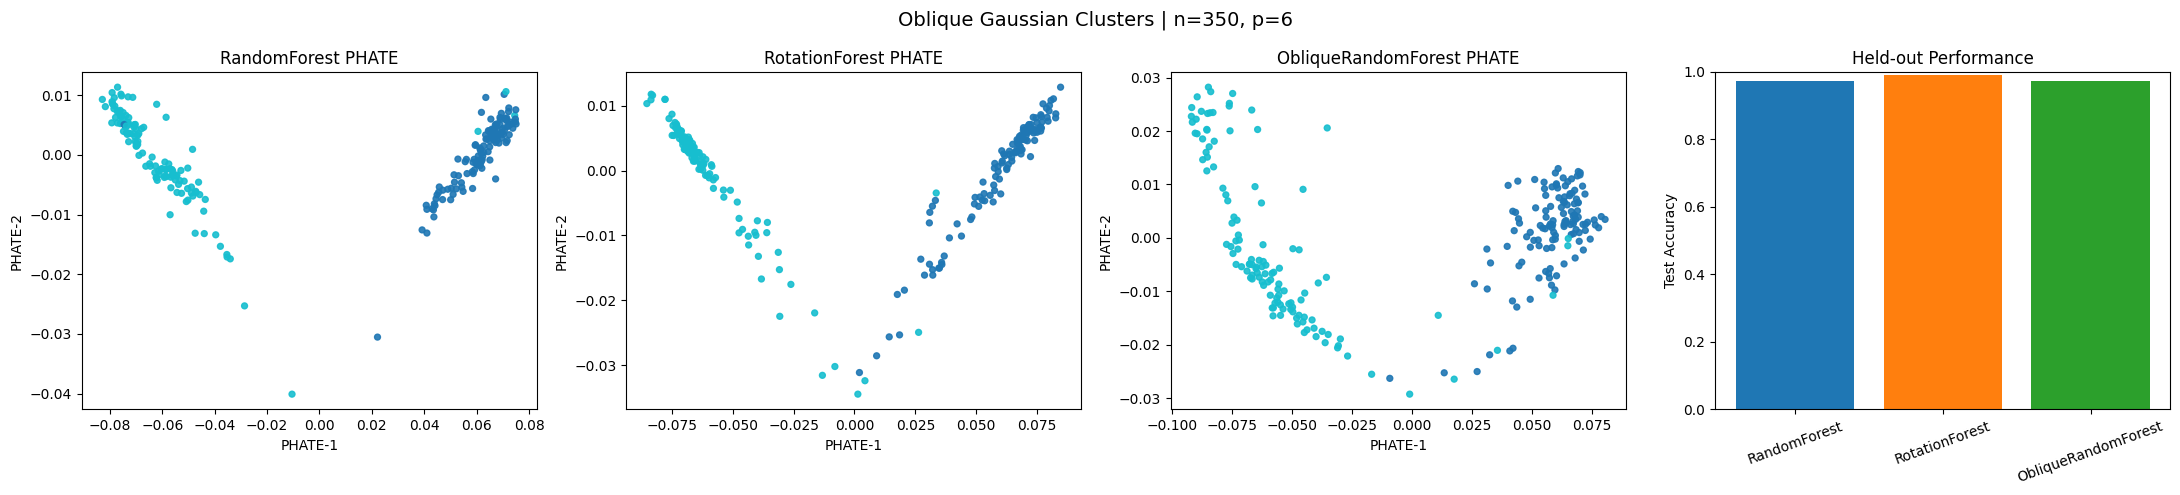

Running simulation: rotated_subspace_signal
Calculating PHATE...
  Running PHATE on 280 observations and 280 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.13 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.02 seconds.
    Calculating affinities...
    Calculated affinities in 0.01 seconds.
  Calculated graph and diffusion operator in 0.17 seconds.
  Calculating optimal t...
    Automatically selected t = 16
  Calculated optimal t in 0.12 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 3.9% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.41 seconds.
Calculated PHATE in 0.71 seconds.
Calculating PHATE...
  Running PHATE on 280 observations and 280 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.12 seconds.
    Calculati

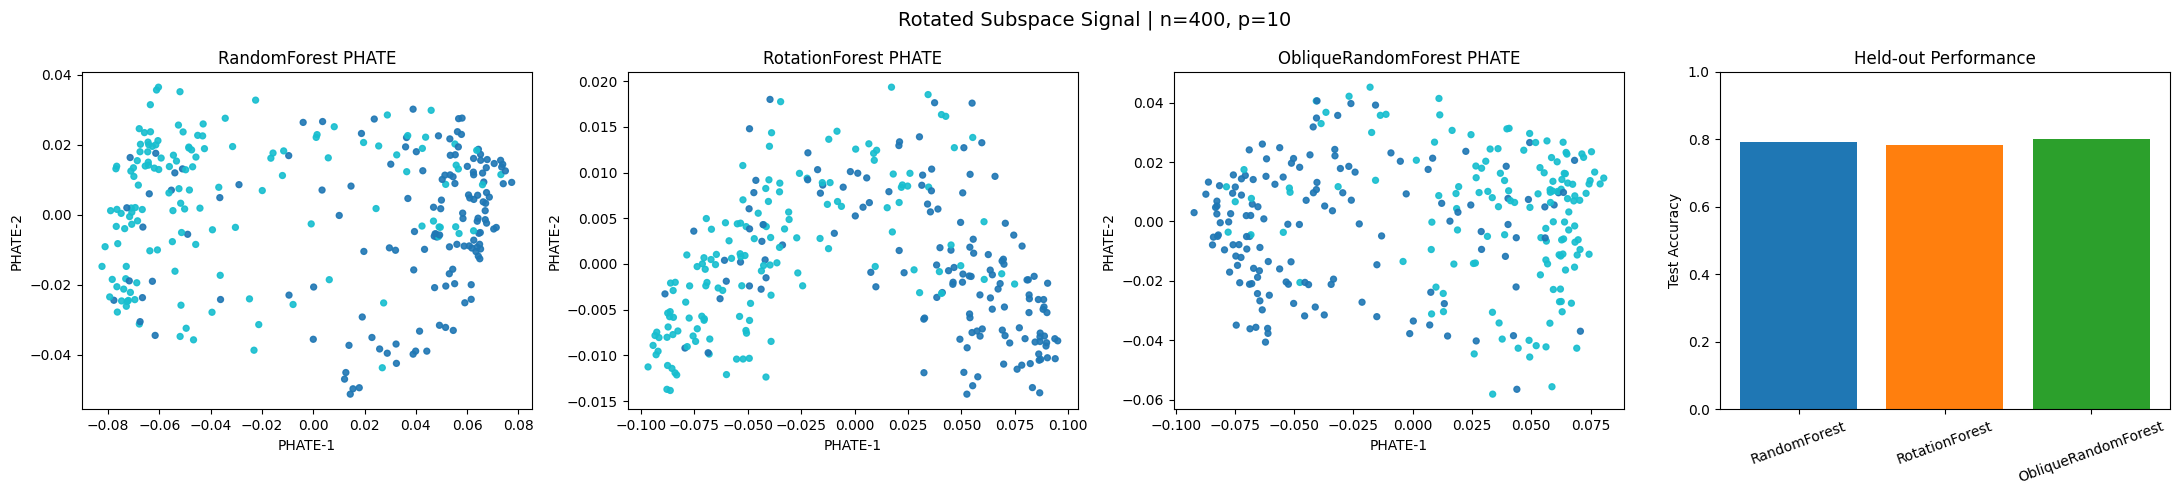

Running simulation: additive_interaction_correlated
Calculating PHATE...
  Running PHATE on 280 observations and 280 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.12 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.02 seconds.
    Calculating affinities...
    Calculated affinities in 0.01 seconds.
  Calculated graph and diffusion operator in 0.16 seconds.
  Calculating optimal t...
    Automatically selected t = 20
  Calculated optimal t in 0.13 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.9% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.37 seconds.
Calculated PHATE in 0.67 seconds.
Calculating PHATE...
  Running PHATE on 280 observations and 280 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.13 seconds.
    

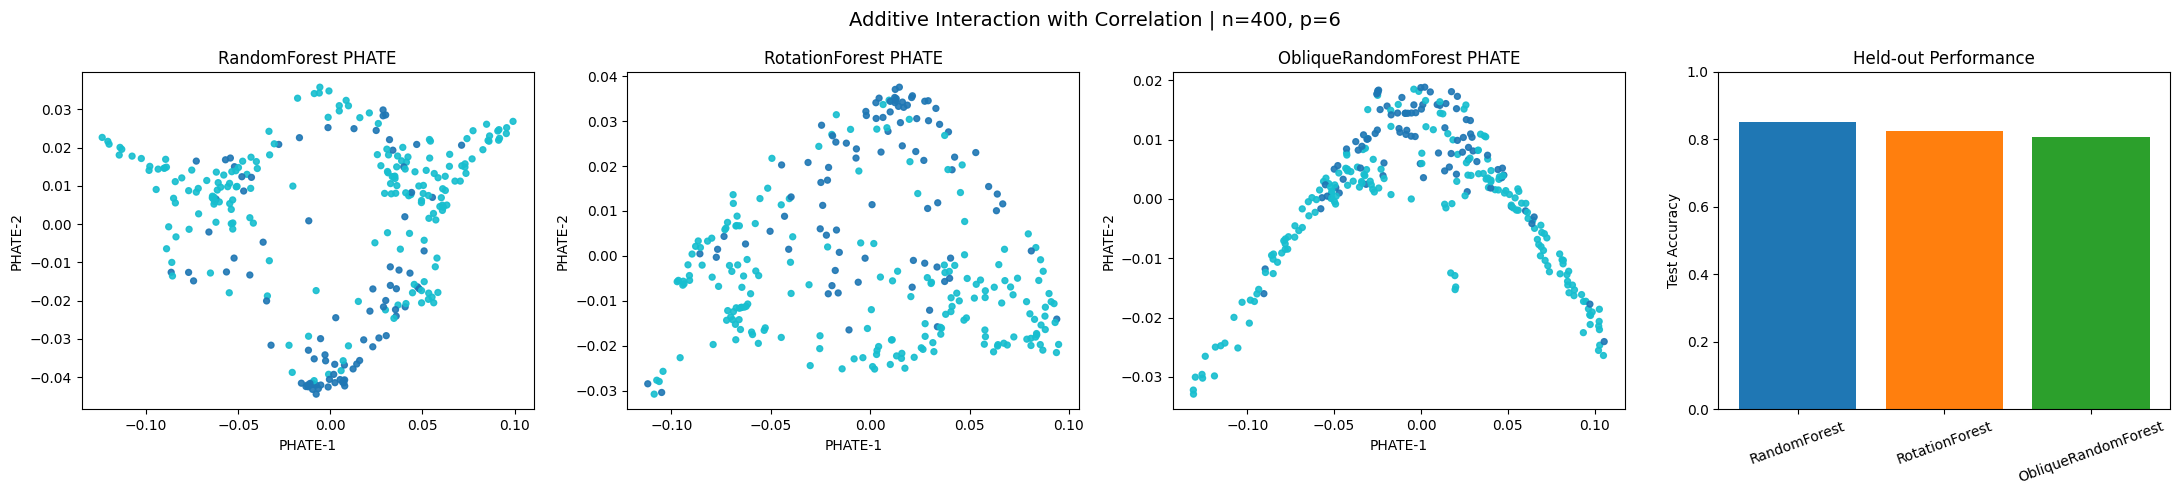

Running simulation: diagonal_band
Calculating PHATE...
  Running PHATE on 245 observations and 245 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.09 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.02 seconds.
    Calculating affinities...
    Calculated affinities in 0.01 seconds.
  Calculated graph and diffusion operator in 0.13 seconds.
  Calculating optimal t...
    Automatically selected t = 20
  Calculated optimal t in 0.12 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 2.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.25 seconds.
Calculated PHATE in 0.51 seconds.
Calculating PHATE...
  Running PHATE on 245 observations and 245 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.10 seconds.
    Calculating KNN sea

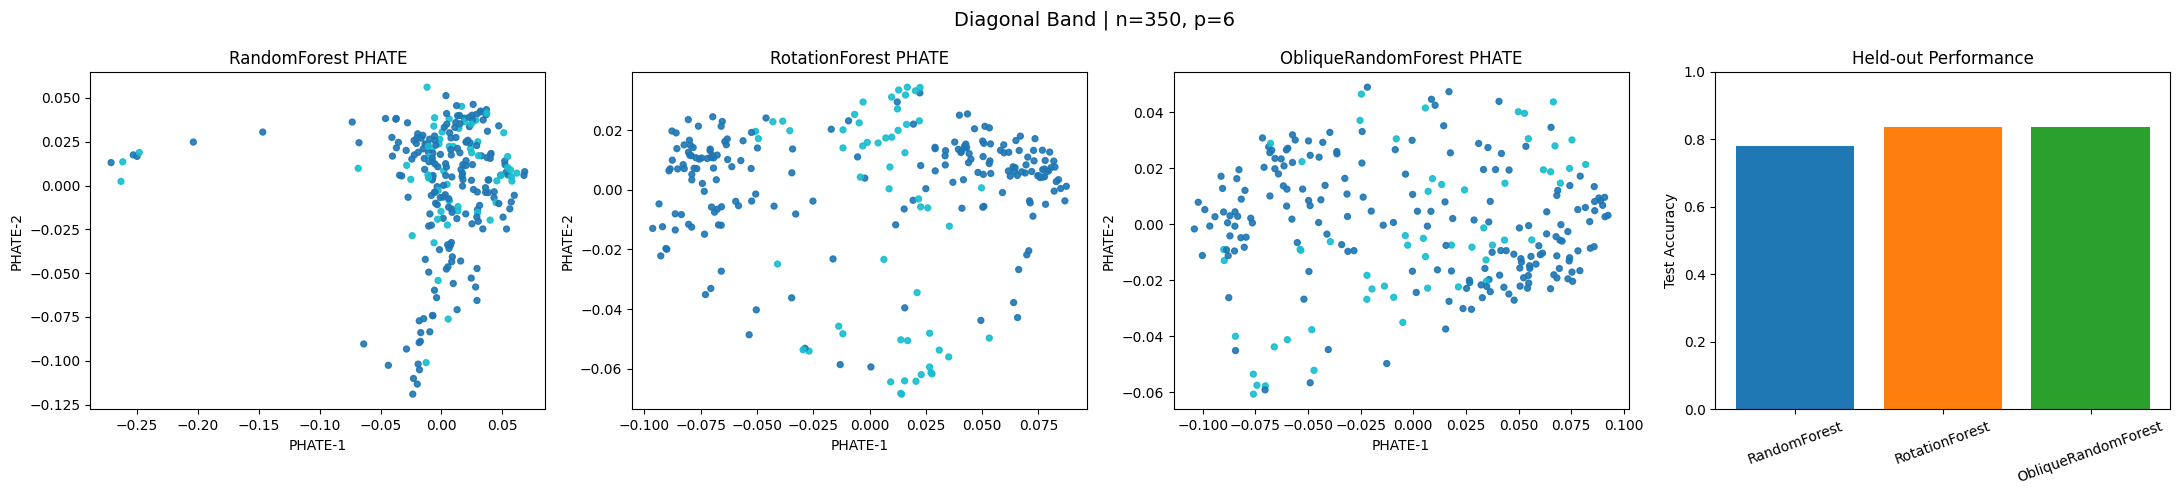

Running simulation: sparse_oblique_hyperplane
Calculating PHATE...
  Running PHATE on 280 observations and 280 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.10 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.02 seconds.
    Calculating affinities...
    Calculated affinities in 0.02 seconds.
  Calculated graph and diffusion operator in 0.14 seconds.
  Calculating optimal t...
    Automatically selected t = 13
  Calculated optimal t in 0.12 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
  Calculated metric MDS in 0.38 seconds.
Calculated PHATE in 0.66 seconds.
Calculating PHATE...
  Running PHATE on 280 observations and 280 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.11 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.02 seconds.
    Calculating affinities...
    Calculated affinities in 0.02 seconds.


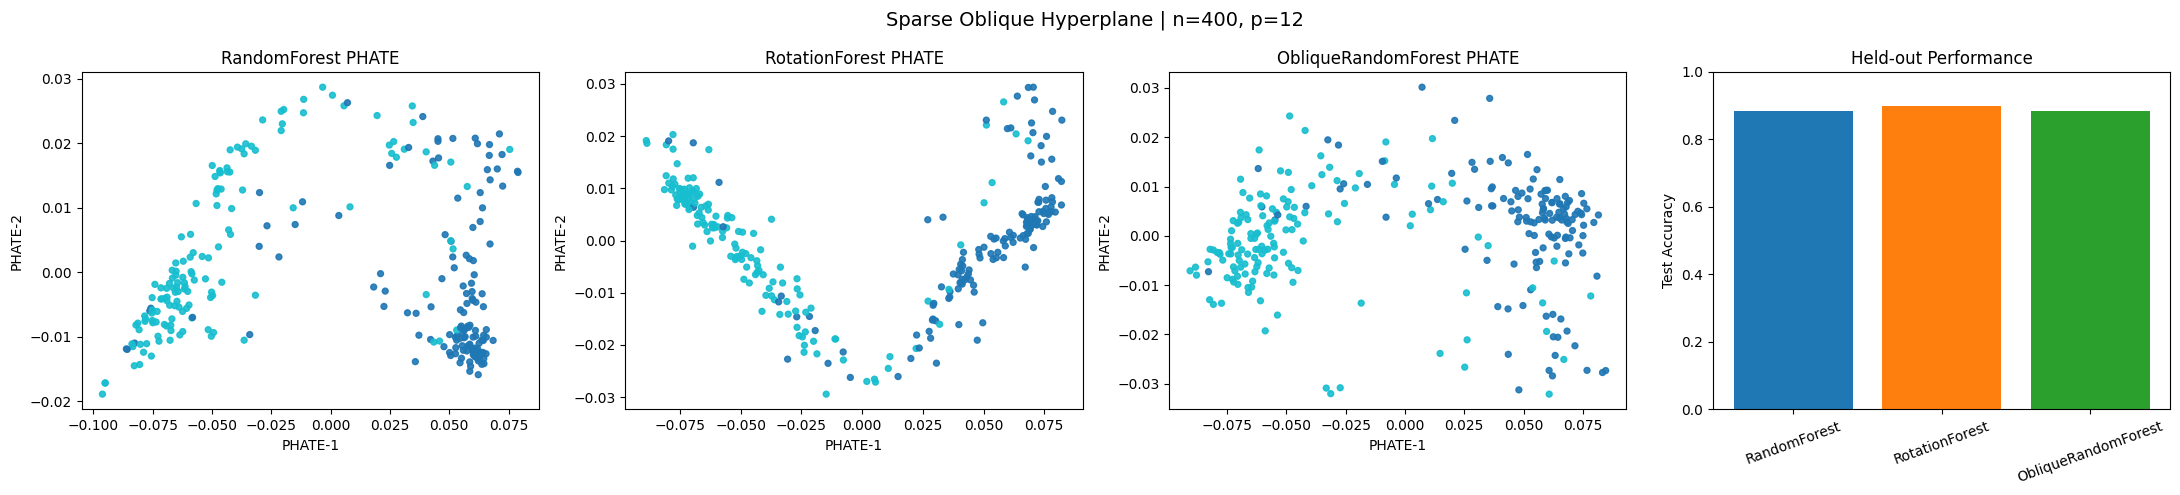

Running simulation: oblique_slab
Calculating PHATE...
  Running PHATE on 280 observations and 280 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.11 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.02 seconds.
    Calculating affinities...
    Calculated affinities in 0.02 seconds.
  Calculated graph and diffusion operator in 0.16 seconds.
  Calculating optimal t...
    Automatically selected t = 19
  Calculated optimal t in 0.13 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 2.0% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.37 seconds.
Calculated PHATE in 0.66 seconds.
Calculating PHATE...
  Running PHATE on 280 observations and 280 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.11 seconds.
    Calculating KNN sear

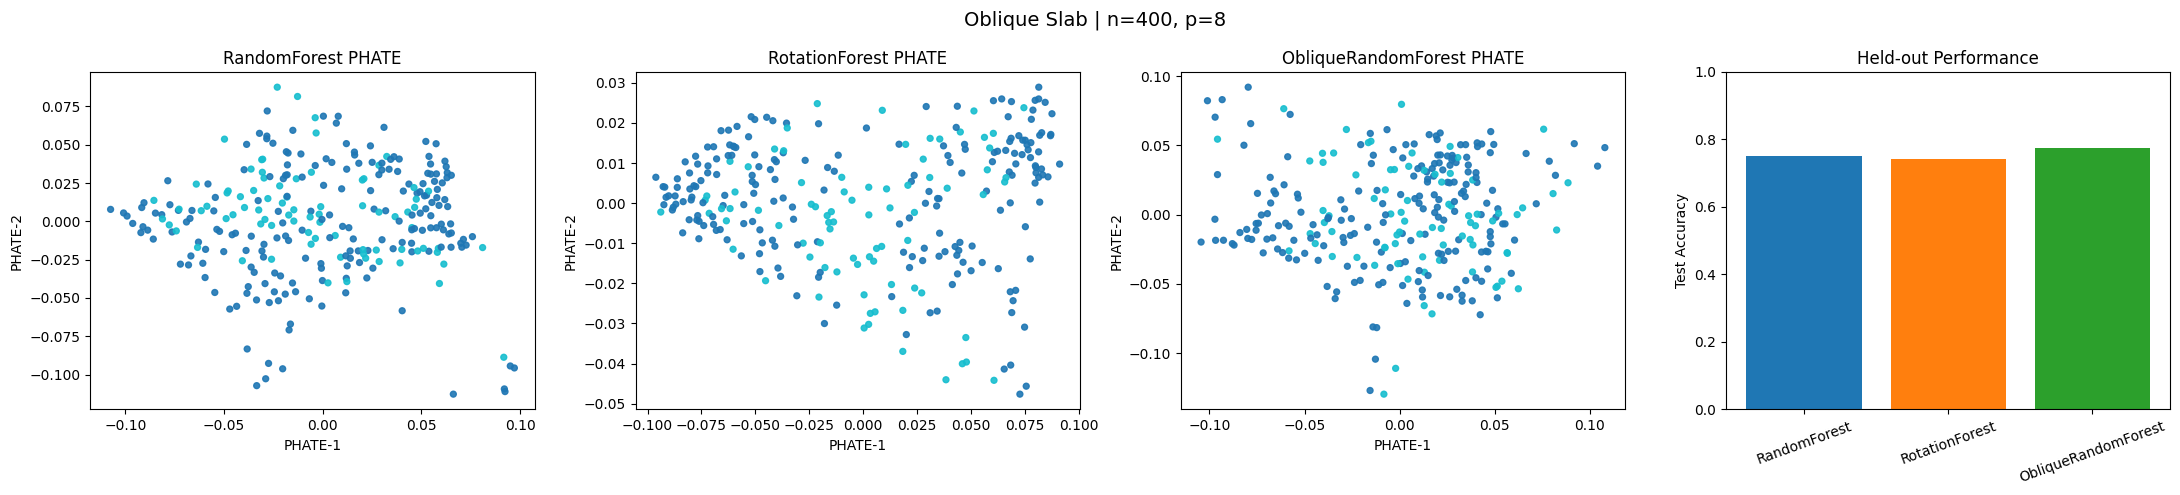

Running simulation: dual_projection_xor
Calculating PHATE...
  Running PHATE on 280 observations and 280 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.12 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.02 seconds.
    Calculating affinities...
    Calculated affinities in 0.01 seconds.
  Calculated graph and diffusion operator in 0.16 seconds.
  Calculating optimal t...
    Automatically selected t = 20
  Calculated optimal t in 0.13 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 10.9% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.36 seconds.
Calculated PHATE in 0.65 seconds.
Calculating PHATE...
  Running PHATE on 280 observations and 280 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.13 seconds.
    Calculating 

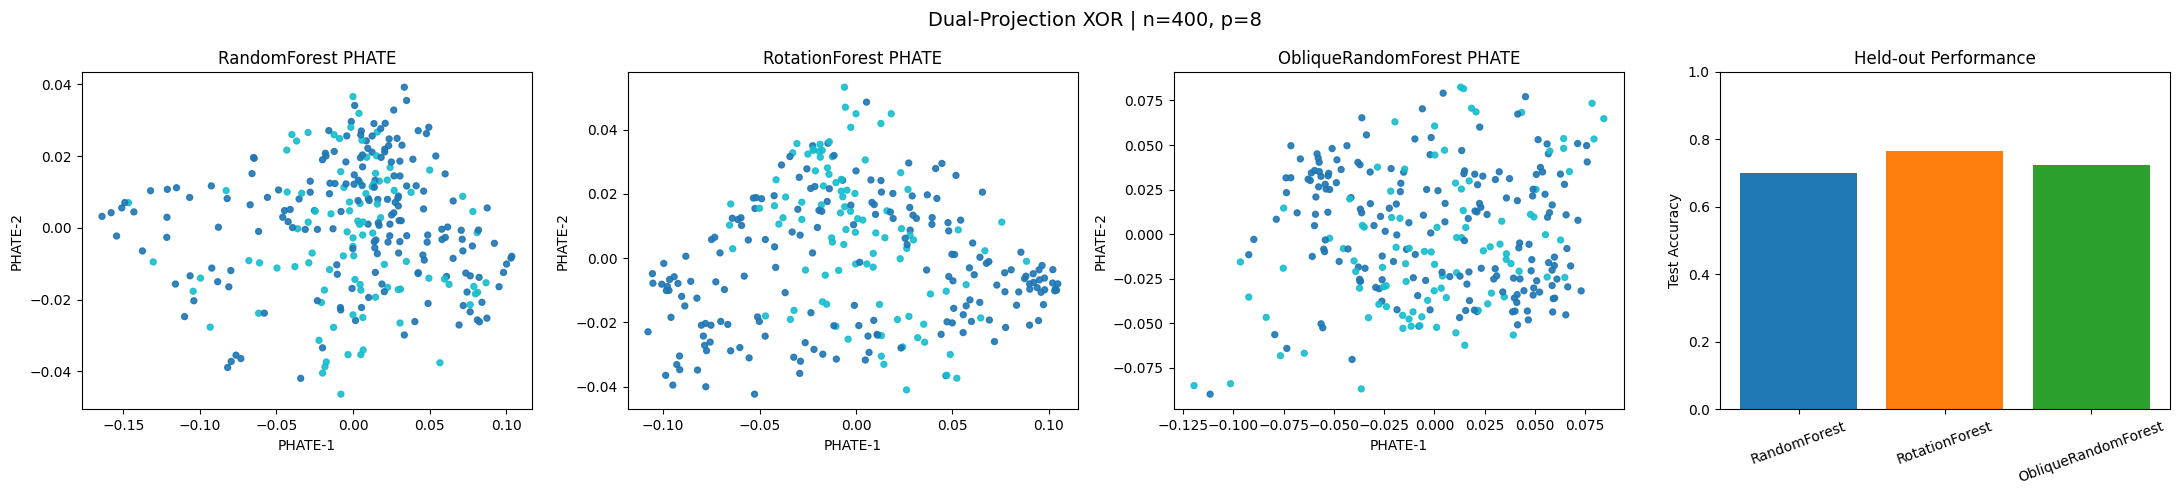

,dataset,model,accuracy
0,Rotated Linear Boundary,RandomForest,0.904762
1,Rotated Linear Boundary,RotationForest,0.914286
2,Rotated Linear Boundary,ObliqueRandomForest,0.904762
3,Rotated XOR,RandomForest,0.809524
4,Rotated XOR,RotationForest,0.838095
5,Rotated XOR,ObliqueRandomForest,0.828571
6,Oblique Gaussian Clusters,RandomForest,0.971429
7,Oblique Gaussian Clusters,RotationForest,0.990476
8,Oblique Gaussian Clusters,ObliqueRandomForest,0.971429
9,Rotated Subspace Signal,RandomForest,0.791667


In [4]:
all_rows = []
for simulation_spec in SIMULATION_CONFIGS:
    print(f"Running simulation: {simulation_spec['name']}")
    all_rows.extend(run_single_simulation(simulation_spec))

performance_df = pd.DataFrame(all_rows)
performance_df


In [8]:
pivot_df = performance_df.pivot(index="dataset", columns="model", values="accuracy").round(3)
rank_df = pivot_df.rank(axis=1, ascending=False, method="min")
pivot_df["Average Rank"] = rank_df.mean(axis=1)
pivot_df.sort_values("Average Rank")


model,ObliqueRandomForest,RandomForest,RotationForest,Average Rank
dataset,,,,
Diagonal Band,0.838,0.781,0.838,1.666667
Oblique Gaussian Clusters,0.971,0.971,0.990,1.666667
Rotated Linear Boundary,0.905,0.905,0.914,1.666667
Sparse Oblique Hyperplane,0.883,0.883,0.900,1.666667
Additive Interaction with Correlation,0.808,0.850,0.825,2.000000
Dual-Projection XOR,0.725,0.700,0.767,2.000000
Oblique Slab,0.775,0.750,0.742,2.000000
Rotated Subspace Signal,0.800,0.792,0.783,2.000000
Rotated XOR,0.829,0.810,0.838,2.000000
